# Lab Assignment: Leapfrog Method for an Initial Value Problem

## Aim
In this practical, we use the Leapfrog method to solve a simple oscillation problem. We compare the numerical answer with the exact answer and then check its accuracy and stability.

## Problem
We are given

$$
\frac{dx}{dt}=v, \qquad \frac{dv}{dt}=-\omega_p^2 x
$$

For this problem, we take $\omega_p=1$, with the initial values

$$
x(0)=0.5, \qquad v(0)=0.
$$

The exact position is $x(t)=0.5\cos(t)$, and the exact velocity is $v(t)=-0.5\sin(t)$.

## 1. Importing the required libraries

We only need NumPy for the calculations and Matplotlib for the graphs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

omega_p = 1.0

## 2. Leapfrog method

In this method, position is calculated at whole time steps, while velocity is kept half a time step ahead.

The update equations are

$$
v_{n+1/2}=v_{n-1/2}-h\omega_p^2x_n
$$

$$
x_{n+1}=x_n+h v_{n+1/2}.
$$

Here, `h` is the time step. The function below performs these two updates.

In [2]:
def leapfrog(x, v_half, h):
    v_new = v_half - h * omega_p**2 * x
    x_new = x + h * v_new

    return x_new, v_new

## 3. Starting the calculation

The given velocity is at time zero, but the method needs the velocity half a step before zero. We calculate it using

$$
v_{-1/2}=v_0+\frac{h}{2}\omega_p^2x_0.
$$

We then run the calculation up to $t=20$.

In [3]:
h = 0.1
t_end = 20.0

number_of_steps = int(round(t_end / h))
t = np.arange(number_of_steps + 1) * h

x = np.zeros(number_of_steps + 1)
v_half = np.zeros(number_of_steps)

x[0] = 0.5
v = 0.0 + 0.5 * h * omega_p**2 * x[0]

for n in range(number_of_steps):
    x[n + 1], v = leapfrog(x[n], v, h)
    v_half[n] = v

t_half = t[:-1] + h / 2

## 4. Comparing with the exact solution

The following graphs show the numerical result and the exact result together. If the method is working well, the two curves should stay close to each other.

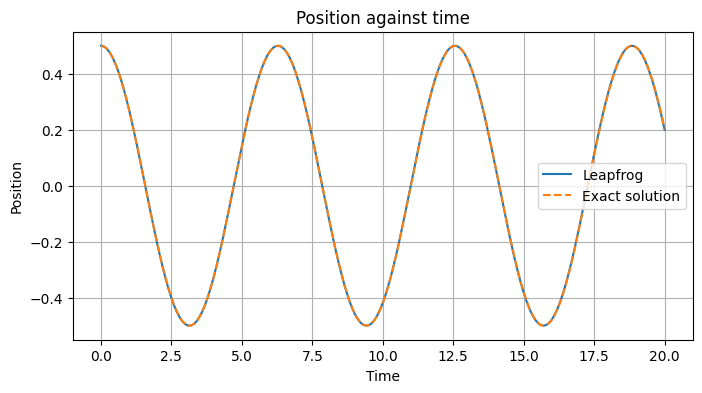

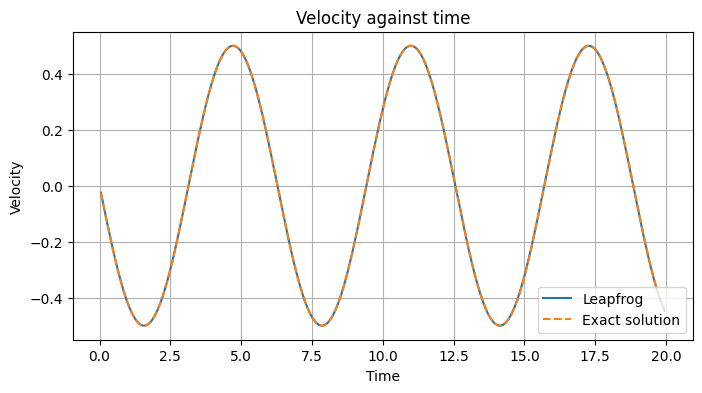

Maximum position error: 0.0038152808690173623
Maximum velocity error: 0.00393146012390859


In [4]:
x_exact = 0.5 * np.cos(omega_p * t)
v_exact = -0.5 * np.sin(omega_p * t_half)

plt.figure(figsize=(8, 4))
plt.plot(t, x, label="Leapfrog")
plt.plot(t, x_exact, "--", label="Exact solution")
plt.xlabel("Time")
plt.ylabel("Position")
plt.title("Position against time")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(t_half, v_half, label="Leapfrog")
plt.plot(t_half, v_exact, "--", label="Exact solution")
plt.xlabel("Time")
plt.ylabel("Velocity")
plt.title("Velocity against time")
plt.grid()
plt.legend()
plt.show()

position_error = np.max(np.abs(x - x_exact))
velocity_error = np.max(np.abs(v_half - v_exact))

print("Maximum position error:", position_error)
print("Maximum velocity error:", velocity_error)

## 5. Convergence test

Now we repeat the calculation using smaller time steps. We compare the numerical position with the exact position and find the maximum error.

We also calculate the observed order:

$$
p=\frac{\log(E(h)/E(h/2))}{\log(2)}.
$$

For a second-order method, the value of `p` should be close to 2 when the time step is small enough.

In [5]:
def solve(h, staggered=True, t_end=20.0):
    number_of_steps = int(round(t_end / h))
    times = np.arange(number_of_steps + 1) * h

    positions = np.zeros(number_of_steps + 1)
    positions[0] = 0.5
    if staggered:
        v = 0.5 * h * omega_p**2 * positions[0]
    else:
        v = 0.0

    for n in range(number_of_steps):
        positions[n + 1], v = leapfrog(positions[n], v, h)

    return times, positions


step_sizes = [0.2, 0.1, 0.05, 0.025]

for staggered in [True, False]:
    errors = []

    for h in step_sizes:
        times, positions = solve(h, staggered)
        exact = 0.5 * np.cos(omega_p * times)
        errors.append(np.max(np.abs(positions - exact)))

    if staggered:
        print("Staggered starting velocity")
    else:
        print("Without staggered starting velocity")

    print("h          Maximum error       Order")
    for i in range(len(step_sizes)):
        if i == 0:
            print(f"{step_sizes[i]:<10} {errors[i]:.6e}       -")
        else:
            order = np.log(errors[i-1] / errors[i]) / np.log(2)
            print(f"{step_sizes[i]:<10} {errors[i]:.6e}       {order:.3f}")
    print()

Staggered starting velocity
h          Maximum error       Order
0.2        1.539615e-02       -
0.1        3.815281e-03       2.013
0.05       9.516946e-04       2.003
0.025      2.377905e-04       2.001

Without staggered starting velocity
h          Maximum error       Order
0.2        6.455709e-02       -
0.1        2.862828e-02       1.173
0.05       1.340166e-02       1.095
0.025      6.475403e-03       1.049



The staggered start should give an error that decreases roughly as $h^2$. Without the half-step correction, the starting error is larger and the observed order is generally lower.

## 6. Order of accuracy

We can remove velocity from the two Leapfrog update equations:

$$
v_{n+1/2}=\frac{x_{n+1}-x_n}{h},
\qquad
v_{n-1/2}=\frac{x_n-x_{n-1}}{h}.
$$

Putting these into the velocity update gives

$$
x_{n+1}-2x_n+x_{n-1}=-h^2\omega_p^2x_n.
$$

Using Taylor expansions around $t_n$,

$$
\frac{x_{n+1}-2x_n+x_{n-1}}{h^2}
=x''(t_n)+O(h^2).
$$

So the central-difference formula, and the properly started Leapfrog method, are second-order accurate.

## 7. Stability test

For this problem, the stability condition is

$$
\boxed{\omega_p h<2}.
$$

We test time steps just below and just above this limit. Below the limit, the oscillation stays bounded. Above it, the numerical solution grows and becomes unstable.

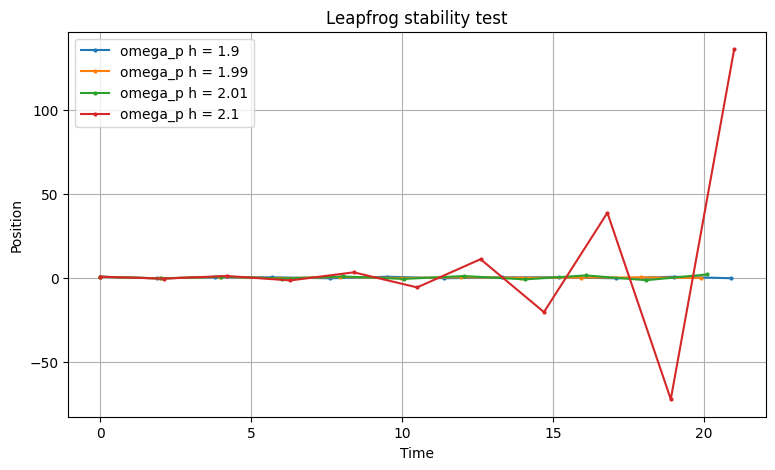

In [6]:
test_steps = [1.9, 1.99, 2.01, 2.1]

plt.figure(figsize=(9, 5))

for h_test in test_steps:
    times, positions = solve(h_test, staggered=True)
    plt.plot(times, positions, "o-", markersize=2,
             label=f"omega_p h = {omega_p * h_test}")

plt.xlabel("Time")
plt.ylabel("Position")
plt.title("Leapfrog stability test")
plt.grid()
plt.legend()
plt.show()

## 8. Conclusion

In this practical, we used the Leapfrog method to solve the given oscillation problem. The numerical position and velocity were compared with the exact solution, and the errors were calculated.

The convergence test showed why the half-step starting velocity is important. With the correct staggered start, the method gives second-order accuracy. The stability test also showed that the time step must satisfy $\omega_p h<2$ for the solution to remain stable.